# 实验一：数据预处理

何霖洁 · 2410311413 · 计算机科学与技术

教学实验日志。学生逐步操作并解释结果；助手补充说明与材料整理。重启 dm-labs 内核后，学生报告全部运行成功，保存的 16 个代码单元编号为 1–16，无 error 输出。

## 复现与方法约定

在 VS Code 选择 dm-labs，重启内核后从头运行全部单元。固定随机种子 42；缺失概率 0.07。保留原始特征和目标，不将类别纳入插补或缩放。缺失方法从共同输入独立处理，后续演示选均值填充支路，不表示它效果最优。比较统计量 std 使用 ddof=1；Z-score 和 StandardScaler 使用 ddof=0。

数据为 sklearn 内置 Wine，无需外部下载。具体步骤、限制、思考题见 实验报告.md，依赖见 requirements.txt。图片与表格由 prepare_submission.py 从保存输出原样提取，不重跑代码。不得把本例人工随机缺失的结论直接推广到真实非随机缺失。


## 1. 环境核对

确认 Notebook 实际使用 dm-labs。


In [1]:
import sys
print(sys.executable)

c:\Users\Qxi\miniconda3\envs\dm-labs\python.exe


## 2. Wine 数据加载

178 个样本、13 个特征，目标单独保存；类别数量为 59、71、48。


In [2]:
import pandas as pd
from sklearn.datasets import load_wine

wine = load_wine()
X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = pd.Series(wine.target, name="target")

print("特征表形状：", X.shape)
print("类别标签数量：", y.shape)
print("各类别样本数：")
print(y.value_counts().sort_index())
print("缺失单元格总数：", X.isna().sum().sum())

display(X.head())

特征表形状： (178, 13)
类别标签数量： (178,)
各类别样本数：
target
0    59
1    71
2    48
Name: count, dtype: int64
缺失单元格总数： 0


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


## 3. 数据摘要

全部特征为数值型；不同列尺度不同。


In [3]:
X.info()
display(X.describe().T)

<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
dtypes: float64(13)
m

,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


## 4. 特征直方图

20 个分箱；malic_acid 右偏，修正了最初对称的预测。


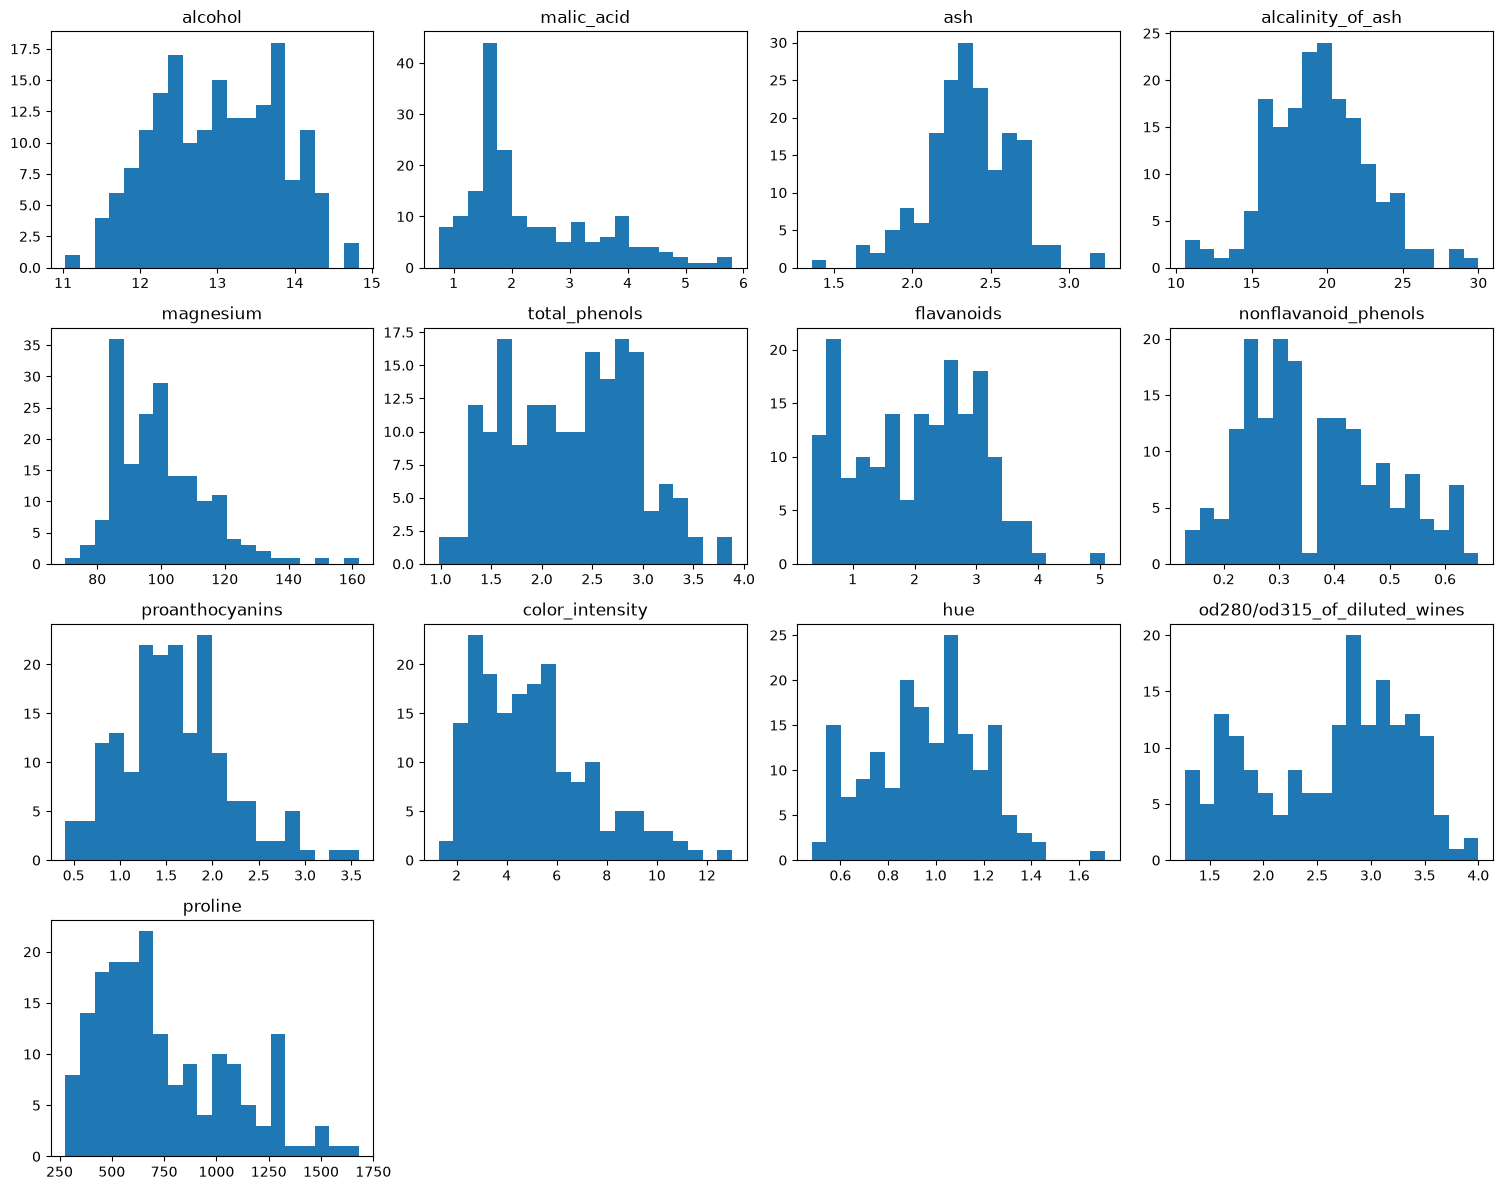

In [4]:
import matplotlib.pyplot as plt

X.hist(bins=20, figsize=(15, 12), grid=False)
plt.tight_layout()
plt.show()

## 5. 原始箱线图

独立点依据 IQR 边界，橙线是中位数，标记不等于错误。


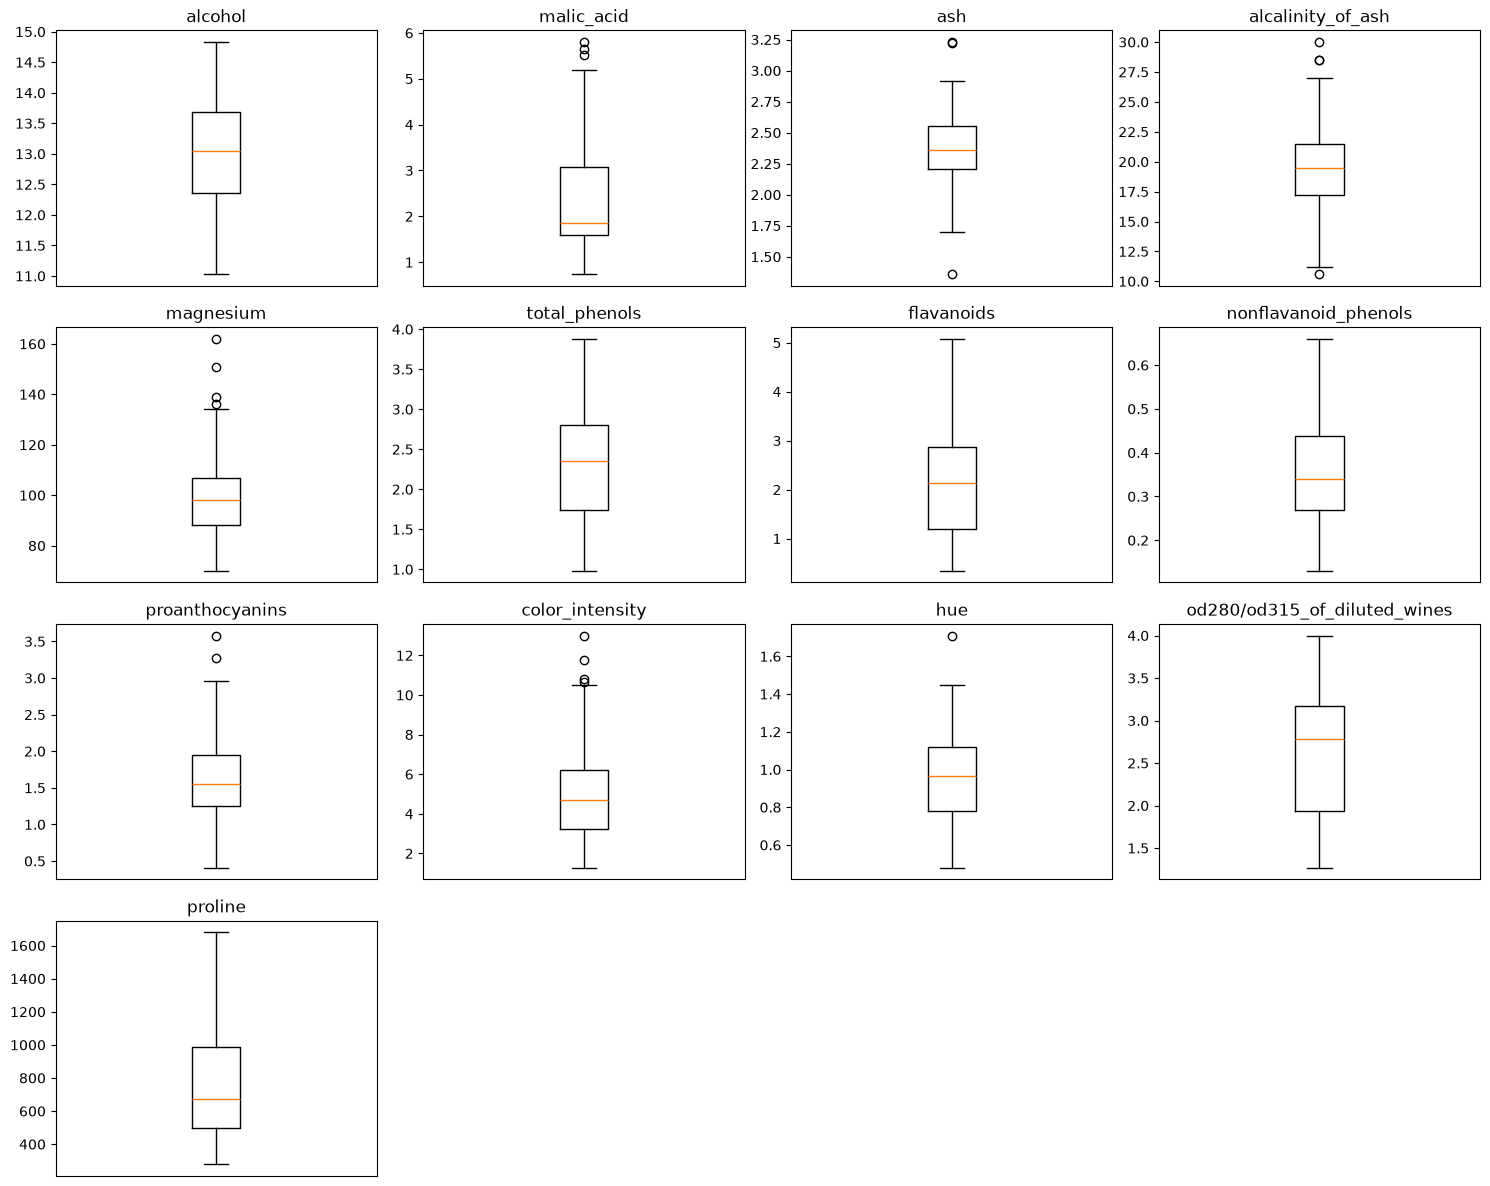

In [5]:
fig, axes = plt.subplots(4, 4, figsize=(15, 12))

for ax, column in zip(axes.flat, X.columns):
    ax.boxplot(X[column], whis=1.5)
    ax.set_title(column)
    ax.set_xticks([])

for ax in axes.flat[len(X.columns):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

## 6. Pearson 相关热力图

相关不等于因果；0.09 为很弱的正线性相关。


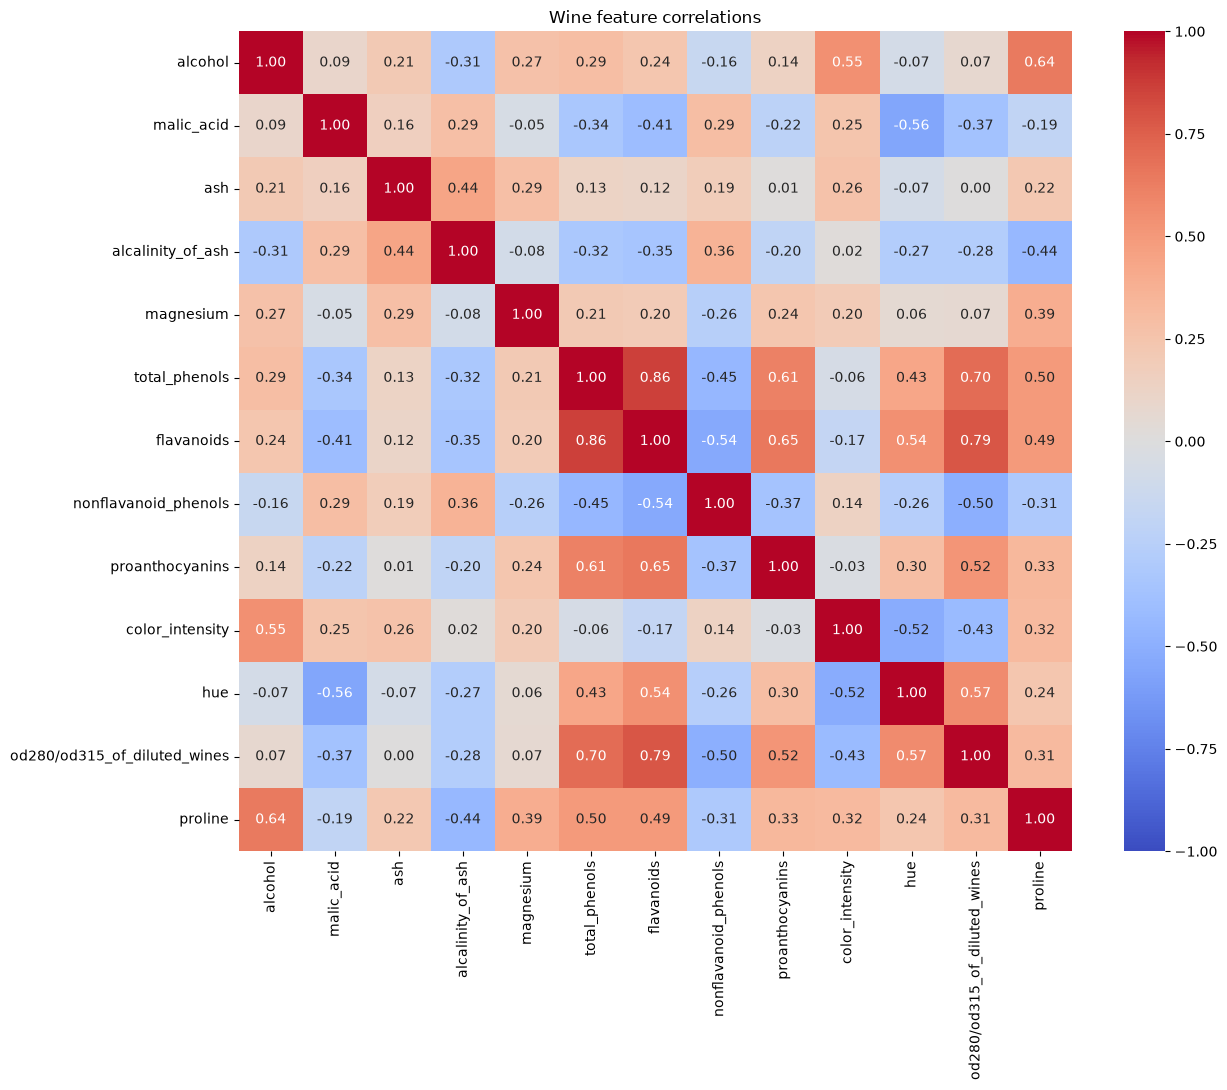

In [6]:
import seaborn as sns

corr = X.corr(method="pearson")

plt.figure(figsize=(13, 11))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)
plt.title("Wine feature correlations")
plt.tight_layout()
plt.show()

## 7. 随机缺失注入

随机种子 42、单元格独立缺失概率 0.07；实际 156 个缺失，涉及 100 行。


In [7]:
import numpy as np

rng = np.random.default_rng(42)
missing_mask = rng.random(X.shape) < 0.07
X_missing = X.mask(missing_mask)

missing_summary = pd.DataFrame({
    "missing_count": X_missing.isna().sum(),
    "missing_percent": X_missing.isna().mean() * 100
})
display(missing_summary)

missing_count = int(X_missing.isna().sum().sum())
affected_rows = int(X_missing.isna().any(axis=1).sum())

print("缺失单元格数：", missing_count)
print(f"实际缺失比例：{missing_count / X.size:.2%}")
print("含缺失值的行数：", affected_rows)
print(f"删除整行将损失：{affected_rows / len(X):.2%}")
print("删除后剩余行数：", len(X) - affected_rows)
print("原始 X 的缺失数：", int(X.isna().sum().sum()))

,missing_count,missing_percent
alcohol,10,5.617978
malic_acid,9,5.056180
ash,9,5.056180
alcalinity_of_ash,11,6.179775
magnesium,16,8.988764
total_phenols,13,7.303371
flavanoids,9,5.056180
nonflavanoid_phenols,14,7.865169
proanthocyanins,16,8.988764
color_intensity,14,7.865169


缺失单元格数： 156
实际缺失比例：6.74%
含缺失值的行数： 100
删除整行将损失：56.18%
删除后剩余行数： 78
原始 X 的缺失数： 0


## 8. 三种缺失处理

共同输入 X_missing；删除剩 78 行，填充保留 178 行。std 默认 ddof=1。


In [8]:
X_drop = X_missing.dropna()
X_mean = X_missing.fillna(X_missing.mean())
X_median = X_missing.fillna(X_missing.median())

datasets = {
    "original": X,
    "missing": X_missing,
    "drop": X_drop,
    "mean": X_mean,
    "median": X_median
}

checks = pd.DataFrame({
    name: {
        "rows": len(data),
        "missing_cells": int(data.isna().sum().sum())
    }
    for name, data in datasets.items()
}).T
display(checks)

comparison = pd.concat({
    name: data.agg(["mean", "std"]).T
    for name, data in datasets.items()
}, axis=1)

display(comparison.round(4))

,rows,missing_cells
original,178,0
missing,178,156
drop,78,0
mean,178,0
median,178,0


original             missing            \
                                  mean       std      mean       std   
alcohol                        13.0006    0.8118   13.0121    0.8224   
malic_acid                      2.3363    1.1171    2.3121    1.1034   
ash                             2.3665    0.2743    2.3679    0.2770   
alcalinity_of_ash              19.4949    3.3396   19.5102    3.3902   
magnesium                      99.7416   14.2825   99.8025   14.3876   
total_phenols                   2.2951    0.6259    2.2833    0.6313   
flavanoids                      2.0293    0.9989    1.9943    0.9913   
nonflavanoid_phenols            0.3619    0.1245    0.3645    0.1242   
proanthocyanins                 1.5909    0.5724    1.5777    0.5693   
color_intensity                 5.0581    2.3183    4.9562    2.2944   
hue                             0.9574    0.2286    0.9590    0.2290   
od280/od315_of_diluted_wines    2.6117    0.7100    2.5940    0.7112   
proline                       746.8933  314.9075  745.0491  314.2302   

                                  drop                mean            \
                                  mean       std      mean       std   
alcohol                        12.9226    0.7788   13.0121    0.7989   
malic_acid                      2.4294    1.1360    2.3121    1.0750   
ash                             2.3976    0.2858    2.3679    0.2699   
alcalinity_of_ash              19.8615    3.3717   19.5102    3.2832   
magnesium                      98.8077   12.7606   99.8025   13.7220   
total_phenols                   2.2755    0.5909    2.2833    0.6077   
flavanoids                      2.0115    1.0126    1.9943    0.9658   
nonflavanoid_phenols            0.3814    0.1254    0.3645    0.1192   
proanthocyanins                 1.5481    0.5525    1.5777    0.5429   
color_intensity                 4.7786    2.1494    4.9562    2.2018   
hue                             0.9605    0.2299    0.9590    0.2231   
od280/od315_of_diluted_wines    2.6162    0.7222    2.5940    0.6888   
proline                       704.5256  285.7552  745.0491  300.6206   

                                median            
                                  mean       std  
alcohol                        13.0142    0.7989  
malic_acid                      2.2877    1.0802  
ash                             2.3675    0.2699  
alcalinity_of_ash              19.5096    3.2832  
magnesium                      99.6404   13.7317  
total_phenols                   2.2860    0.6078  
flavanoids                      1.9966    0.9658  
nonflavanoid_phenols            0.3625    0.1193  
proanthocyanins                 1.5747    0.5430  
color_intensity                 4.9282    2.2039  
hue                             0.9591    0.2231  
od280/od315_of_diluted_wines    2.6049    0.6901  
proline                       738.8933  301.3086

## 9. 异常注入

复制 X_mean，第 0 行 magnesium 从 127 改为 1000；记录前后值。


In [9]:
X_outlier = X_mean.copy()

row = 0
column = "magnesium"
before_value = X_outlier.loc[row, column]
before_mean = X_outlier[column].mean()

X_outlier.loc[row, column] = 1000.0

injection_record = pd.DataFrame([{
    "row": row,
    "feature": column,
    "before": before_value,
    "after": X_outlier.loc[row, column]
}])
display(injection_record)

print("注入前均值：", before_mean)
print("注入后均值：", X_outlier[column].mean())
print("X_mean 对应位置仍为：", X_mean.loc[row, column])
print("剩余缺失数：", int(X_outlier.isna().sum().sum()))

,row,feature,before,after
0,0,magnesium,127.0,1000.0


注入前均值： 99.80246913580248
注入后均值： 104.70696351782495
X_mean 对应位置仍为： 127.0
剩余缺失数： 0


## 10. IQR 与 Z-score 检测

共同输入 X_outlier；标记 42/13 个单元格；Z-score 使用 ddof=0。


In [10]:
q1 = X_outlier.quantile(0.25)
q3 = X_outlier.quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
iqr_mask = (X_outlier < lower) | (X_outlier > upper)

# 使用总体标准差（ddof=0）；恒定列避免除以零
std = X_outlier.std(ddof=0).replace(0, np.nan)
z_scores = (X_outlier - X_outlier.mean()) / std
z_mask = z_scores.abs() > 3

display(pd.DataFrame({
    "IQR_count": iqr_mask.sum(),
    "Z_score_count": z_mask.sum()
}))

print("注入点被 IQR 标记：", iqr_mask.loc[0, "magnesium"])
print("注入点被 Z-score 标记：", z_mask.loc[0, "magnesium"])

print("IQR 异常单元格数：", int(iqr_mask.sum().sum()))
print("IQR 涉及样本行数：", int(iqr_mask.any(axis=1).sum()))
print("Z-score 异常单元格数：", int(z_mask.sum().sum()))
print("Z-score 涉及样本行数：", int(z_mask.any(axis=1).sum()))

,IQR_count,Z_score_count
alcohol,0,0
malic_acid,5,2
ash,5,3
alcalinity_of_ash,5,1
magnesium,6,1
total_phenols,0,0
flavanoids,0,1
nonflavanoid_phenols,0,0
proanthocyanins,7,1
color_intensity,9,2


注入点被 IQR 标记： True
注入点被 Z-score 标记： True
IQR 异常单元格数： 42
IQR 涉及样本行数： 38
Z-score 异常单元格数： 13
Z-score 涉及样本行数： 12


## 11. 四分位数手算

magnesium：Q1=89，Q3=106；手算 IQR=17、边界 [63.5, 131.5]。


In [11]:
print("magnesium 的 Q1：", q1["magnesium"])
print("magnesium 的 Q3：", q3["magnesium"])

magnesium 的 Q1： 89.0
magnesium 的 Q3： 106.0


## 12. 固定 IQR 边界盖帽

修改 42 个单元格，1000→131.5，保留 178×13；未超出原固定边界。


盖帽后的形状： (178, 13)
修改的单元格数： 42
仍超出原边界的数量： 0
注入点盖帽后： 131.5
处理前副本仍为： 1000.0
剩余缺失数： 0


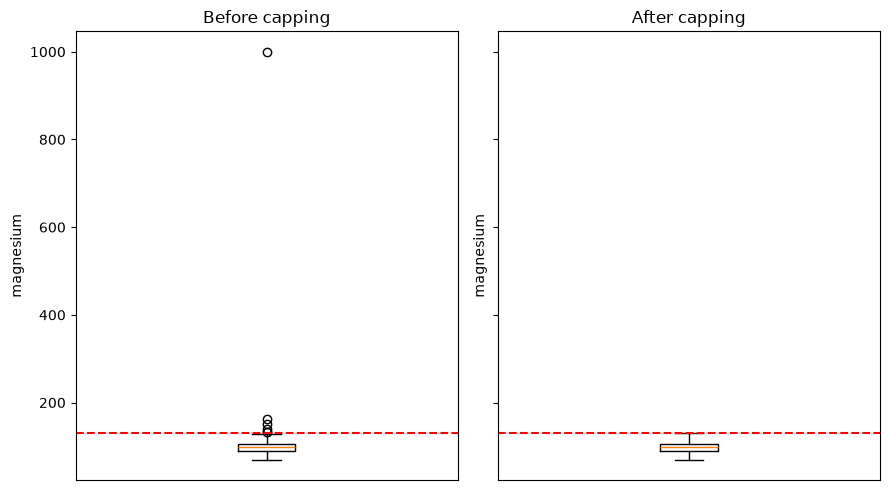

In [12]:
X_capped = X_outlier.clip(lower=lower, upper=upper, axis=1)

changed = X_capped.ne(X_outlier)
outside = (X_capped < lower) | (X_capped > upper)

print("盖帽后的形状：", X_capped.shape)
print("修改的单元格数：", int(changed.sum().sum()))
print("仍超出原边界的数量：", int(outside.sum().sum()))
print("注入点盖帽后：", X_capped.loc[0, "magnesium"])
print("处理前副本仍为：", X_outlier.loc[0, "magnesium"])
print("剩余缺失数：", int(X_capped.isna().sum().sum()))

fig, axes = plt.subplots(1, 2, figsize=(9, 5), sharey=True)

axes[0].boxplot(X_outlier["magnesium"], whis=1.5)
axes[0].set_title("Before capping")

axes[1].boxplot(X_capped["magnesium"], whis=1.5)
axes[1].set_title("After capping")

for ax in axes:
    ax.set_ylabel("magnesium")
    ax.set_xticks([])
    ax.axhline(upper["magnesium"], color="red", linestyle="--")

plt.tight_layout()
plt.show()

## 13. 两种缩放与数值检查

分别拟合 X_capped；Min-Max 范围 [0,1]，Z-score 均值约 0、总体标准差约 1。


In [13]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

X_minmax = pd.DataFrame(
    MinMaxScaler().fit_transform(X_capped),
    columns=X_capped.columns,
    index=X_capped.index
)

X_zscore = pd.DataFrame(
    StandardScaler().fit_transform(X_capped),
    columns=X_capped.columns,
    index=X_capped.index
)

scaling_summary = pd.DataFrame({
    "MinMax_min": X_minmax.min(),
    "MinMax_max": X_minmax.max(),
    "Z_mean": X_zscore.mean(),
    "Z_std": X_zscore.std(ddof=0)
})
display(scaling_summary.round(6))

print("Min-Max 形状：", X_minmax.shape)
print("Z-score 形状：", X_zscore.shape)
print("Min-Max 最小值约为 0：", np.allclose(X_minmax.min(), 0))
print("Min-Max 最大值约为 1：", np.allclose(X_minmax.max(), 1))
print("Z-score 均值约为 0：", np.allclose(X_zscore.mean(), 0))
print("Z-score 总体标准差约为 1：",
      np.allclose(X_zscore.std(ddof=0), 1))

,MinMax_min,MinMax_max,Z_mean,Z_std
alcohol,0.0,1.0,-0.0,1.0
malic_acid,0.0,1.0,-0.0,1.0
ash,0.0,1.0,0.0,1.0
alcalinity_of_ash,0.0,1.0,-0.0,1.0
magnesium,0.0,1.0,-0.0,1.0
total_phenols,0.0,1.0,0.0,1.0
flavanoids,0.0,1.0,0.0,1.0
nonflavanoid_phenols,0.0,1.0,0.0,1.0
proanthocyanins,0.0,1.0,-0.0,1.0
color_intensity,0.0,1.0,0.0,1.0


Min-Max 形状： (178, 13)
Z-score 形状： (178, 13)
Min-Max 最小值约为 0： True
Min-Max 最大值约为 1： True
Z-score 均值约为 0： True
Z-score 总体标准差约为 1： True


## 14. 缩放前后图形对比

尺度统一不代表各特征分布相同；均值为零不要求中位数为零。


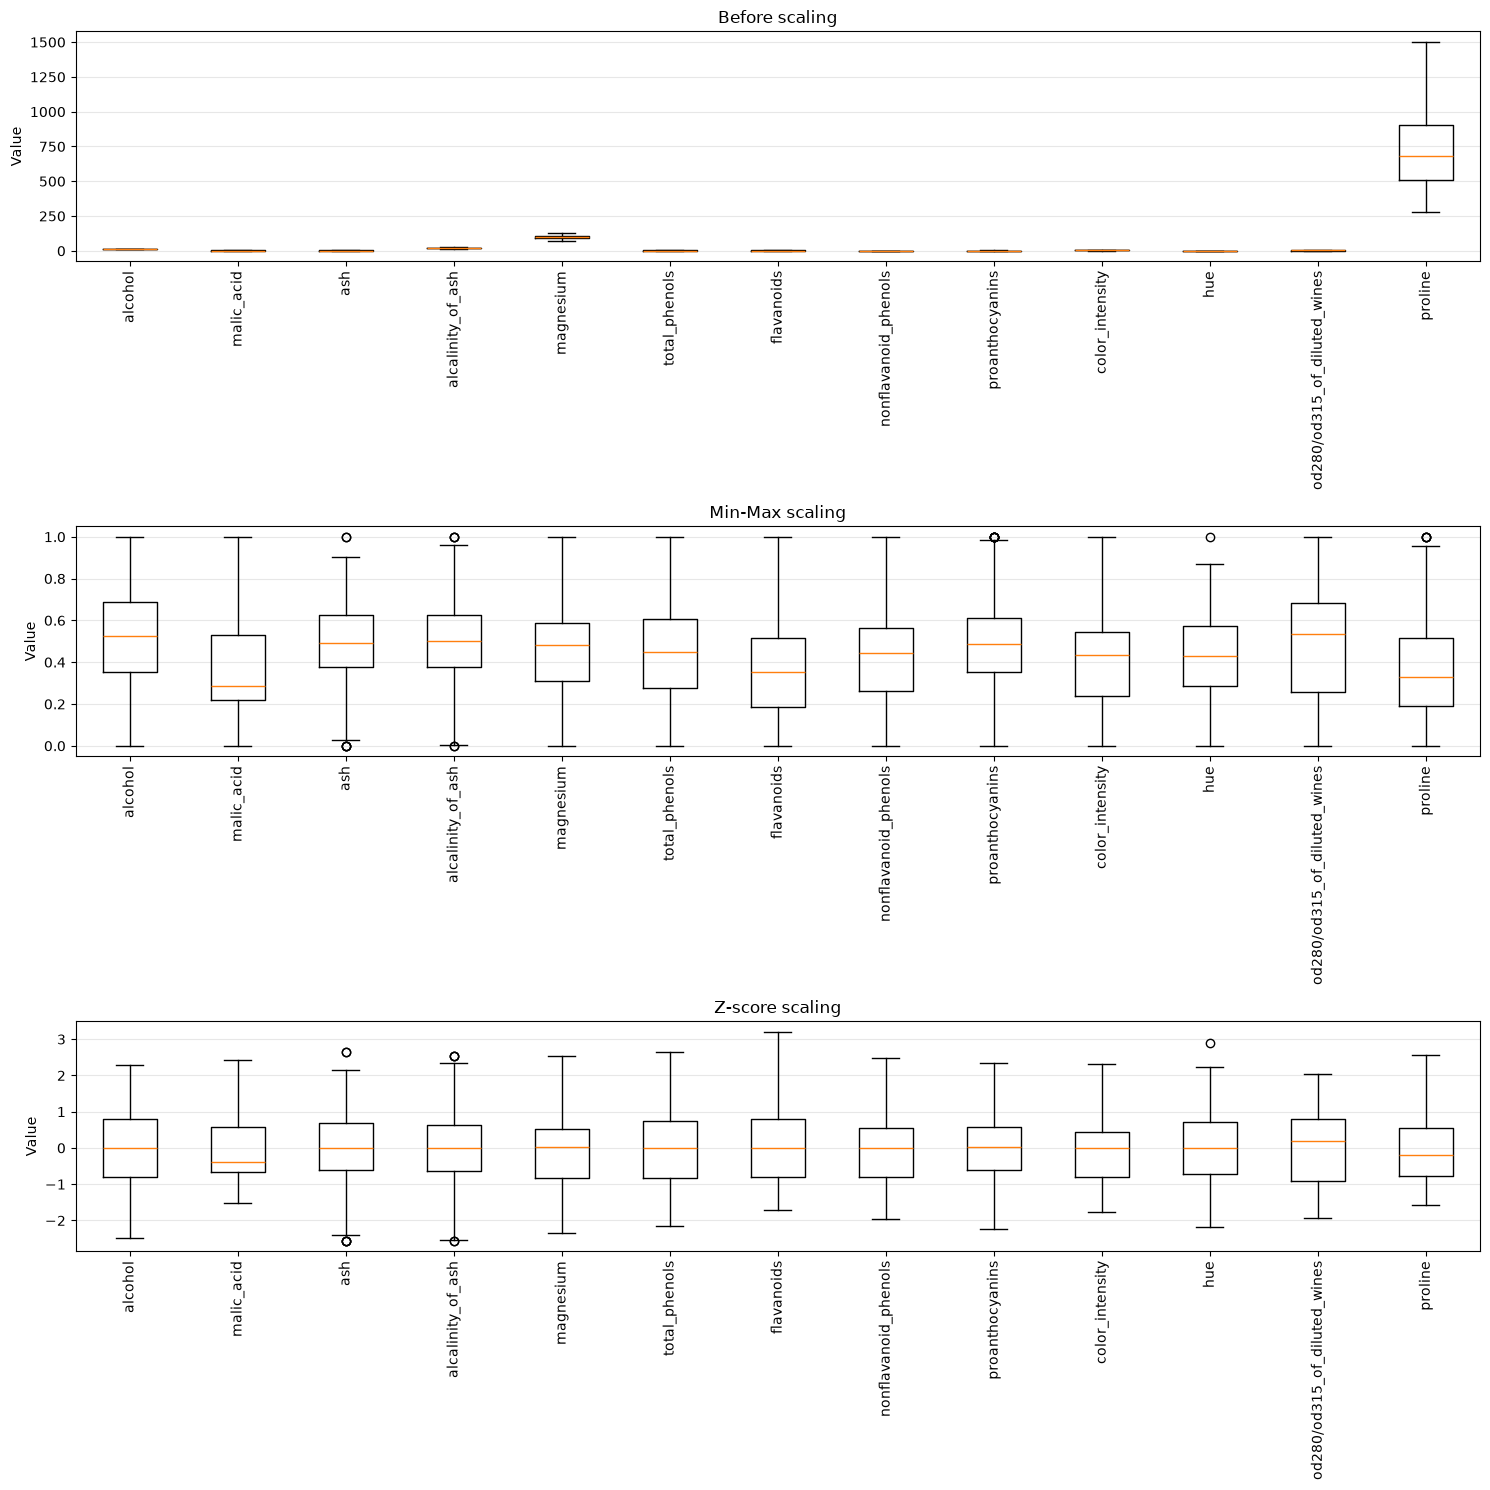

In [14]:
fig, axes = plt.subplots(3, 1, figsize=(15, 15))

plot_data = [
    (X_capped, "Before scaling"),
    (X_minmax, "Min-Max scaling"),
    (X_zscore, "Z-score scaling")
]

for ax, (data, title) in zip(axes, plot_data):
    ax.boxplot(data.to_numpy(), tick_labels=data.columns)
    ax.set_title(title)
    ax.set_ylabel("Value")
    ax.tick_params(axis="x", labelrotation=90)
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## 15. Wine 目标独热编码

形状 178×3，每行之和为 1，索引与特征表对齐。


In [15]:
y_onehot = pd.get_dummies(y, prefix="class", dtype=int)

display(pd.concat([y, y_onehot], axis=1).head())

print("编码表形状：", y_onehot.shape)
print("每行之和都为 1：", y_onehot.sum(axis=1).eq(1).all())
print("索引与特征表对齐：", y_onehot.index.equals(X_capped.index))

# 每个类别各取一个样本，核对编码映射
example_indices = y.drop_duplicates().index
display(pd.concat([y, y_onehot], axis=1).loc[example_indices])

,target,class_0,class_1,class_2
0,0,1,0,0
1,0,1,0,0
2,0,1,0,0
3,0,1,0,0
4,0,1,0,0


编码表形状： (178, 3)
每行之和都为 1： True
索引与特征表对齐： True


,target,class_0,class_1,class_2
0,0,1,0,0
59,1,0,1,0
130,2,0,0,1


## 16. 标签编码对照演示

独立颜色样例：blue=0、green=1、red=2；编号差不代表真实距离。


In [16]:
from sklearn.preprocessing import LabelEncoder

# 独立演示数据，不加入 Wine 特征
colors = pd.Series(["red", "green", "blue", "red"], name="color")

encoder = LabelEncoder()
label_codes = encoder.fit_transform(colors)
onehot_codes = pd.get_dummies(colors, prefix="color", dtype=int)

display(pd.concat([
    colors,
    pd.Series(label_codes, name="label_code"),
    onehot_codes
], axis=1))

print("标签映射：", dict(zip(
    encoder.classes_,
    encoder.transform(encoder.classes_)
)))

,color,label_code,color_blue,color_green,color_red
0,red,2,0,0,1
1,green,1,0,1,0
2,blue,0,1,0,0
3,red,2,0,0,1


标签映射： {'blue': np.int64(0), 'green': np.int64(1), 'red': np.int64(2)}
